In [4]:
import pandas as pd
import json

EXPERIMENT_NAME = 'Aug29'

# Define the paths for your training and testing datasets
train_paths = [
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L2.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L3.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L4.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L5.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L6.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L7.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L8.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L9.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L10.jsonl',
               '../data/' + EXPERIMENT_NAME + '/2_DyF_L11.jsonl'
               ]
test_path = '../data/' + EXPERIMENT_NAME + '/2_DyF_L1.jsonl'

# Create empty lists to store data
train_data_list = []
test_data_list = []

# Load training data
for path in train_paths:
    with open(path, 'r') as f:
        for line in f:
            train_data_list.append(json.loads(line))

# Load testing data
with open(test_path, 'r') as f:
    for line in f:
        test_data_list.append(json.loads(line))

# Create DataFrames
train_df = pd.DataFrame(train_data_list)
test_df = pd.DataFrame(test_data_list)

# Print the head of the training and testing DataFrames
print("Training Data Head:")
print(train_df.head())
print("\nTesting Data Head:")
print(test_df.head())

Training Data Head:
      timestamp  delta_time  \
0  1.756487e+09    0.001774   
1  1.756487e+09    0.004041   
2  1.756487e+09    0.003929   
3  1.756487e+09    0.003978   
4  1.756487e+09    0.003999   

                                                 POS  \
0  [0.34404176369455874, -0.05416166530810974, 0....   
1  [0.344041769833246, -0.054161663557730624, 0.3...   
2  [0.3440417737938125, -0.054161674905429565, 0....   
3  [0.3440417815873066, -0.054161685925307436, 0....   
4  [0.3440417909383939, -0.054161696391576454, 0....   

                                                FRaw  \
0  [0.9936548691101367, 3.7755921681657556, 12.12...   
1  [0.9764122189901041, 3.767495137771636, 12.105...   
2  [0.970751502084398, 3.743386085492829, 12.1127...   
3  [0.993848521666561, 3.7534552675705197, 12.103...   
4  [1.0043886563768911, 3.7656801481301043, 12.07...   

                                               FF_EE  \
0  [0.9879126072567948, 3.7641955158122897, 12.11...   
1  [0.9

Specific correlation heatmap saved as 'specific_correlation_heatmap.png'


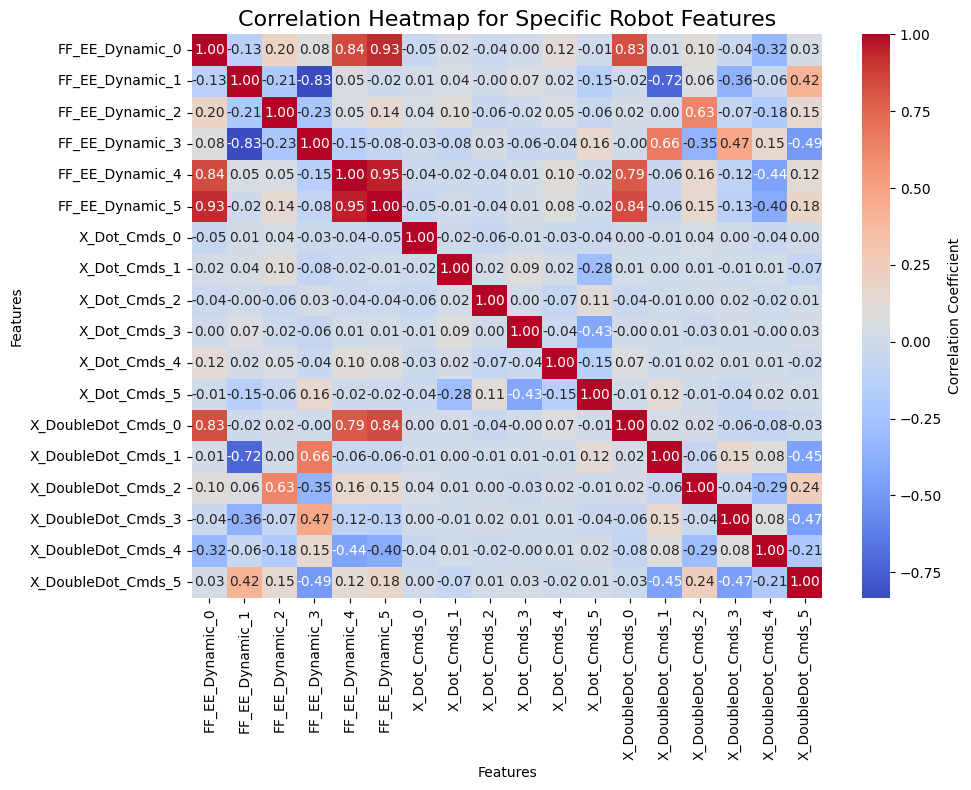

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# A robust function to flatten list-like columns
def flatten_columns(df):
    df_copy = df.copy()
    columns_to_flatten = ['POS','FF_EE_Dynamic', 'X_Dot_Cmds', 'X_DoubleDot_Cmds']
    
    for col in columns_to_flatten:
        if col in df_copy.columns:
            try:
                # Use df.apply(pd.Series) to efficiently flatten the list
                flattened_data = df_copy[col].apply(pd.Series)
                # Rename columns
                flattened_data.columns = [f'{col}_{i}' for i in flattened_data.columns]
                # Drop the original list column and concatenate the new columns
                df_copy = pd.concat([df_copy.drop(col, axis=1), flattened_data], axis=1)
            except Exception as e:
                print(f"Could not flatten column {col}. Error: {e}")
                # Drop the column if it causes an error to prevent the corr() error
                df_copy = df_copy.drop(col, axis=1)
    return df_copy

# Select only the columns of interest from the training DataFrame
columns_of_interest = ['FF_EE_Dynamic', 'X_Dot_Cmds', 'X_DoubleDot_Cmds']
filtered_train_df = train_df[columns_of_interest].copy()

# Flatten the selected columns
flattened_train_df = flatten_columns(filtered_train_df)

# Calculate the correlation matrix
correlation_matrix = flattened_train_df.corr(numeric_only=True)

# Set up the matplotlib figure for a more compact heatmap
plt.figure(figsize=(10, 8))

# Draw the heatmap with a custom colormap
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm',
            cbar_kws={'label': 'Correlation Coefficient'})

# Add a title and labels
plt.title('Correlation Heatmap for Specific Robot Features', fontsize=16)
plt.xlabel('Features')
plt.ylabel('Features')

# Adjust layout
plt.tight_layout()

# Save the figure to a file
plt.savefig('specific_correlation_heatmap.png')
print("Specific correlation heatmap saved as 'specific_correlation_heatmap.png'")

In [ ]:
import pandas as pd
import json
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import numpy as np
from tqdm import tqdm

# A robust function to flatten any list-like columns
def flatten_all_columns(df):
    df_copy = df.copy()
    
    # Identify all columns that contain lists
    list_cols = [col for col in df_copy.columns if not df_copy[col].empty and isinstance(df_copy[col].iloc[0], list)]
    
    for col in list_cols:
        try:
            flattened_data = df_copy[col].apply(pd.Series)
            flattened_data.columns = [f'{col}_{i}' for i in flattened_data.columns]
            df_copy = pd.concat([df_copy.drop(col, axis=1), flattened_data], axis=1)
        except Exception as e:
            print(f"Could not flatten column {col}. Error: {e}")
            df_copy = df_copy.drop(col, axis=1)
    return df_copy

# --- 1. Load and Prepare Data ---
print("Loading and preparing training data...")
train_data_list = []
for path in train_paths:
    with open(path, 'r') as f:
        train_data_list.extend([json.loads(line) for line in f])
train_df = pd.DataFrame(train_data_list)
flattened_train_df = flatten_all_columns(train_df)

print("Loading and preparing testing data...")
with open(test_path, 'r') as f:
    test_data_list = [json.loads(line) for line in f]
test_df = pd.DataFrame(test_data_list)
flattened_test_df = flatten_all_columns(test_df)

# --- 2. Define Features (X) and Target (y) ---
# Use consistent column names for both training and testing sets
feature_cols = ['POS_3', 'POS_4', 'POS_5', 
                'X_DoubleDot_Cmds_0', 'X_DoubleDot_Cmds_1', 'X_DoubleDot_Cmds_2', 
                'X_DoubleDot_Cmds_3', 'X_DoubleDot_Cmds_4', 'X_DoubleDot_Cmds_5']
target_cols = ['FF_EE_Dynamic_0', 'FF_EE_Dynamic_1', 'FF_EE_Dynamic_2', 
               'FF_EE_Dynamic_3', 'FF_EE_Dynamic_4', 'FF_EE_Dynamic_5']

X_train = flattened_train_df[feature_cols]
y_train = flattened_train_df[target_cols]
X_test = flattened_test_df[feature_cols]
y_test = flattened_test_df[target_cols]

# --- 3. Scale the Data ---
# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler on the training features and transform them
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the test features
X_test_scaled = scaler.transform(X_test)
# The target variable (y) does not need to be scaled for this model
# because the output is not constrained to a specific range.

# --- 4. Train the MLP Model with TQDM ---
print("\nTraining MLP Model...")
mlp = MLPRegressor(hidden_layer_sizes=(100, 100), activation='relu', solver='sgd', 
                   max_iter=1, warm_start=True, random_state=42)

for _ in tqdm(range(500), desc="Training MLP"):
    mlp.partial_fit(X_train_scaled, y_train)

# --- 5. Evaluate the Model ---
print("\nEvaluating Model on Test Data...")
# Make predictions on the scaled test set
y_pred = mlp.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"\nMean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

Loading and preparing training data...
Loading and preparing testing data...

Training MLP Model...


Training MLP: 100%|██████████| 500/500 [21:37<00:00,  2.60s/it]


Evaluating Model on Test Data...

Mean Squared Error (MSE): 0.0003
Root Mean Squared Error (RMSE): 0.0172


In [12]:
import numpy as np
from scipy.io import savemat

def export_mlp_to_mat(mlp, scaler, mat_path="force_mlp_params.mat"):
    """
    Exports sklearn MLPRegressor + StandardScaler to a MATLAB .mat file with
    matrices oriented for Simulink matrix multiply: y = W3*ReLU(W2*ReLU(W1*x + b1) + b2) + b3

    Saves as single precision:
      W1: (100, 9)   b1: (100, 1)
      W2: (100, 100) b2: (100, 1)
      W3: (  6, 100) b3: (  6, 1)
      mu: (  9, 1)   invsigma: (9, 1)  where x_scaled = diag(invsigma) * (x - mu)
    """
    # sklearn stores weights as (n_in, n_out). Transpose to (n_out, n_in) for W*x.
    W1 = mlp.coefs_[0].T.astype(np.float32)          # (100, 9)
    b1 = mlp.intercepts_[0].astype(np.float32).reshape(-1, 1)   # (100, 1)

    W2 = mlp.coefs_[1].T.astype(np.float32)          # (100, 100)
    b2 = mlp.intercepts_[1].astype(np.float32).reshape(-1, 1)   # (100, 1)

    W3 = mlp.coefs_[2].T.astype(np.float32)          # (6, 100)
    b3 = mlp.intercepts_[2].astype(np.float32).reshape(-1, 1)   # (6, 1)

    mu = scaler.mean_.astype(np.float32).reshape(-1, 1)         # (9, 1)
    invsigma = (1.0 / scaler.scale_).astype(np.float32).reshape(-1, 1)  # (9, 1)

    # Quick sanity prints
    print("W1", W1.shape, "b1", b1.shape)
    print("W2", W2.shape, "b2", b2.shape)
    print("W3", W3.shape, "b3", b3.shape)
    print("mu", mu.shape, "invsigma", invsigma.shape)

    savemat(mat_path, {
        "W1": W1, "b1": b1,
        "W2": W2, "b2": b2,
        "W3": W3, "b3": b3,
        "mu": mu, "invsigma": invsigma,
    })
    print(f"Saved {mat_path}")

# ---- call it after training ----
export_mlp_to_mat(mlp, scaler, mat_path="force_mlp_params.mat")


W1 (100, 9) b1 (100, 1)
W2 (100, 100) b2 (100, 1)
W3 (6, 100) b3 (6, 1)
mu (9, 1) invsigma (9, 1)
Saved force_mlp_params.mat


In [11]:
# --- 8. Export Model to ONNX Format ---
print("\n" + "="*50)
print("EXPORTING MODEL TO ONNX FORMAT")
print("="*50)

# Define file names at the beginning
ONNX_MODEL_FILENAME = '../models/' + EXPERIMENT_NAME + '/kuka_force_predictor.onnx'

try:
    import onnxmltools
    from skl2onnx import convert_sklearn
    from skl2onnx.common.data_types import FloatTensorType
    
    # Define the input shape for ONNX
    # Your model expects 9 features: [POS_0, POS_1, POS_2, X_DoubleDot_Cmds_0, ..., X_DoubleDot_Cmds_5]
    input_shape = (None, 9)  # (batch_size, num_features)
    
    # Convert the sklearn MLP model to ONNX with Opset 14
    initial_type = [('float_input', FloatTensorType(input_shape))]
    
    # Convert the model with Opset 14
    onx = convert_sklearn(mlp, initial_types=initial_type, 
                         target_opset=14)  # Opset 14
    
    # Set IR version to 7
    onx.ir_version = 7
    
    # Save the ONNX model
    with open(ONNX_MODEL_FILENAME, "wb") as f:
        f.write(onx.SerializeToString())
    
    print(f"✅ Model successfully exported to: {ONNX_MODEL_FILENAME}")
    print(f"   Input shape: {input_shape}")
    print(f"   Output shape: (batch_size, 6) - 6 force components")
    print(f"   Opset version: 14")
    print(f"   IR version: 7")
    
    # Verify the ONNX model
    import onnx
    onnx_model = onnx.load(ONNX_MODEL_FILENAME)
    onnx.checker.check_model(onnx_model)
    print("✅ ONNX model validation passed!")
    
    # Print model info
    print(f"\nModel Information:")
    print(f"   Input: {onnx_model.graph.input[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.input[0].type.tensor_type.shape.dim]}")
    print(f"   Output: {onnx_model.graph.output[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.output[0].type.tensor_type.shape.dim]}")
    print(f"   Opset: {onnx_model.opset_import[0].version}")
    print(f"   IR Version: {onnx_model.ir_version}")
    
except ImportError as e:
    print("❌ Missing required packages. Install them with:")
    print("   pip install onnxmltools skl2onnx onnx")
    print(f"   Error: {e}")
    
except Exception as e:
    print(f"❌ Error during ONNX conversion: {e}")
    print("   This might happen if your model has unsupported operations")

import scipy.io as sio

sio.savemat('../models/'+EXPERIMENT_NAME+'/mlp_sklearn_extras.mat', {
    'x_mean': scaler.mean_.astype(np.float32).reshape(-1,1),   # (9x1)
    'x_scale': scaler.scale_.astype(np.float32).reshape(-1,1), # (9x1)
})



EXPORTING MODEL TO ONNX FORMAT
✅ Model successfully exported to: ../models/Aug20/kuka_force_predictor.onnx
   Input shape: (None, 9)
   Output shape: (batch_size, 6) - 6 force components
   Opset version: 14
   IR version: 7
✅ ONNX model validation passed!

Model Information:
   Input: float_input - Shape: [0, 9]
   Output: variable - Shape: [0, 1]
   Opset: 14
   IR Version: 7


In [12]:
# PyTorch
dummy = torch.randn(1, 9)  # [batch, features]
torch.onnx.export(model, dummy, "force_mlp.onnx",
                  input_names=["features"], output_names=["force"])


NameError: name 'torch' is not defined

In [ ]:
# --- 8. Export Model to ONNX Format ---
print("\n" + "="*50)
print("EXPORTING MODEL TO ONNX FORMAT")
print("="*50)

# Define file names at the beginning
ONNX_MODEL_FILENAME = '../models/' + EXPERIMENT_NAME + '/kuka_force_predictor.onnx'

try:
    import onnxmltools
    from skl2onnx import convert_sklearn
    from skl2onnx.common.data_types import FloatTensorType
    
    # Define the input shape for ONNX
    # Your model expects 9 features: [POS_0, POS_1, POS_2, X_DoubleDot_Cmds_0, ..., X_DoubleDot_Cmds_5]
    input_shape = (None, 9)  # (batch_size, num_features)
    
    # Convert the sklearn MLP model to ONNX with specific Opset and IR version
    initial_type = [('float_input', FloatTensorType(input_shape))]
    
    # Convert the model with Opset 14 and IR v7
    onx = convert_sklearn(mlp, initial_types=initial_type, 
                         target_opset=14,  # Opset 14
                         target_opset_onnx=14)  # Ensure ONNX opset compatibility
    
    # Set IR version to 7
    onx.ir_version = 7
    
    # Save the ONNX model
    with open(ONNX_MODEL_FILENAME, "wb") as f:
        f.write(onx.SerializeToString())
    
    print(f"✅ Model successfully exported to: {ONNX_MODEL_FILENAME}")
    print(f"   Input shape: {input_shape}")
    print(f"   Output shape: (batch_size, 6) - 6 force components")
    print(f"   Opset version: 14")
    print(f"   IR version: 7")
    
    # Verify the ONNX model
    import onnx
    onnx_model = onnx.load(ONNX_MODEL_FILENAME)
    onnx.checker.check_model(onnx_model)
    print("✅ ONNX model validation passed!")
    
    # Print model info
    print(f"\nModel Information:")
    print(f"   Input: {onnx_model.graph.input[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.input[0].type.tensor_type.shape.dim]}")
    print(f"   Output: {onnx_model.graph.output[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.output[0].type.tensor_type.shape.dim]}")
    print(f"   Opset: {onnx_model.opset_import[0].version}")
    print(f"   IR Version: {onnx_model.ir_version}")
    
except ImportError as e:
    print("❌ Missing required packages. Install them with:")
    print("   pip install onnxmltools skl2onnx onnx")
    print(f"   Error: {e}")
    
except Exception as e:
    print(f"❌ Error during ONNX conversion: {e}")
    print("   This might happen if your model has unsupported operations")


EXPORTING MODEL TO ONNX FORMAT
❌ Error during ONNX conversion: convert_sklearn() got an unexpected keyword argument 'target_opset_onnx'. Did you mean 'target_opset'?
   This might happen if your model has unsupported operations


In [ ]:
# --- 8. Export Model to ONNX Format ---
print("\n" + "="*50)
print("EXPORTING MODEL TO ONNX FORMAT")
print("="*50)

# Define file names at the beginning
ONNX_MODEL_FILENAME = '../models/' + EXPERIMENT_NAME + '/kuka_force_predictor.onnx'

try:
    import onnxmltools
    from skl2onnx import convert_sklearn
    from skl2onnx.common.data_types import FloatTensorType
    
    # Define the input shape for ONNX
    # Your model expects 9 features: [POS_0, POS_1, POS_2, X_DoubleDot_Cmds_0, ..., X_DoubleDot_Cmds_5]
    input_shape = (None, 9)  # (batch_size, num_features)
    
    # Convert the sklearn MLP model to ONNX with specific Opset and IR version
    initial_type = [('float_input', FloatTensorType(input_shape))]
    
    # Convert the model with Opset 14 and IR v7
    onx = convert_sklearn(mlp, initial_types=initial_type, 
                         target_opset=14,  # Opset 14
                         target_opset_onnx=14)  # Ensure ONNX opset compatibility
    
    # Set IR version to 7
    onx.ir_version = 7
    
    # Save the ONNX model
    with open(ONNX_MODEL_FILENAME, "wb") as f:
        f.write(onx.SerializeToString())
    
    print(f"✅ Model successfully exported to: {ONNX_MODEL_FILENAME}")
    print(f"   Input shape: {input_shape}")
    print(f"   Output shape: (batch_size, 6) - 6 force components")
    print(f"   Opset version: 14")
    print(f"   IR version: 7")
    
    # Verify the ONNX model
    import onnx
    onnx_model = onnx.load(ONNX_MODEL_FILENAME)
    onnx.checker.check_model(onnx_model)
    print("✅ ONNX model validation passed!")
    
    # Print model info
    print(f"\nModel Information:")
    print(f"   Input: {onnx_model.graph.input[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.input[0].type.tensor_type.shape.dim]}")
    print(f"   Output: {onnx_model.graph.output[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.output[0].type.tensor_type.shape.dim]}")
    print(f"   Opset: {onnx_model.opset_import[0].version}")
    print(f"   IR Version: {onnx_model.ir_version}")
    
except ImportError as e:
    print("❌ Missing required packages. Install them with:")
    print("   pip install onnxmltools skl2onnx onnx")
    print(f"   Error: {e}")
    
except Exception as e:
    print(f"❌ Error during ONNX conversion: {e}")
    print("   This might happen if your model has unsupported operations")


EXPORTING MODEL TO ONNX FORMAT
❌ Error during ONNX conversion: convert_sklearn() got an unexpected keyword argument 'target_opset_onnx'. Did you mean 'target_opset'?
   This might happen if your model has unsupported operations


In [ ]:
# --- 8. Export Model to ONNX Format ---
print("\n" + "="*50)
print("EXPORTING MODEL TO ONNX FORMAT")
print("="*50)

# Define file names at the beginning
ONNX_MODEL_FILENAME = '../models/' + EXPERIMENT_NAME + '/kuka_force_predictor.onnx'

try:
    import onnxmltools
    from skl2onnx import convert_sklearn
    from skl2onnx.common.data_types import FloatTensorType
    
    # Define the input shape for ONNX
    # Your model expects 9 features: [POS_0, POS_1, POS_2, X_DoubleDot_Cmds_0, ..., X_DoubleDot_Cmds_5]
    input_shape = (None, 9)  # (batch_size, num_features)
    
    # Convert the sklearn MLP model to ONNX with specific Opset and IR version
    initial_type = [('float_input', FloatTensorType(input_shape))]
    
    # Convert the model with Opset 14 and IR v7
    onx = convert_sklearn(mlp, initial_types=initial_type, 
                         target_opset=14,  # Opset 14
                         target_opset_onnx=14)  # Ensure ONNX opset compatibility
    
    # Set IR version to 7
    onx.ir_version = 7
    
    # Save the ONNX model
    with open(ONNX_MODEL_FILENAME, "wb") as f:
        f.write(onx.SerializeToString())
    
    print(f"✅ Model successfully exported to: {ONNX_MODEL_FILENAME}")
    print(f"   Input shape: {input_shape}")
    print(f"   Output shape: (batch_size, 6) - 6 force components")
    print(f"   Opset version: 14")
    print(f"   IR version: 7")
    
    # Verify the ONNX model
    import onnx
    onnx_model = onnx.load(ONNX_MODEL_FILENAME)
    onnx.checker.check_model(onnx_model)
    print("✅ ONNX model validation passed!")
    
    # Print model info
    print(f"\nModel Information:")
    print(f"   Input: {onnx_model.graph.input[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.input[0].type.tensor_type.shape.dim]}")
    print(f"   Output: {onnx_model.graph.output[0].name} - Shape: {[dim.dim_value for dim in onnx_model.graph.output[0].type.tensor_type.shape.dim]}")
    print(f"   Opset: {onnx_model.opset_import[0].version}")
    print(f"   IR Version: {onnx_model.ir_version}")
    
except ImportError as e:
    print("❌ Missing required packages. Install them with:")
    print("   pip install onnxmltools skl2onnx onnx")
    print(f"   Error: {e}")
    
except Exception as e:
    print(f"❌ Error during ONNX conversion: {e}")
    print("   This might happen if your model has unsupported operations")


EXPORTING MODEL TO ONNX FORMAT
❌ Error during ONNX conversion: convert_sklearn() got an unexpected keyword argument 'target_opset_onnx'. Did you mean 'target_opset'?
   This might happen if your model has unsupported operations


KeyboardInterrupt: 

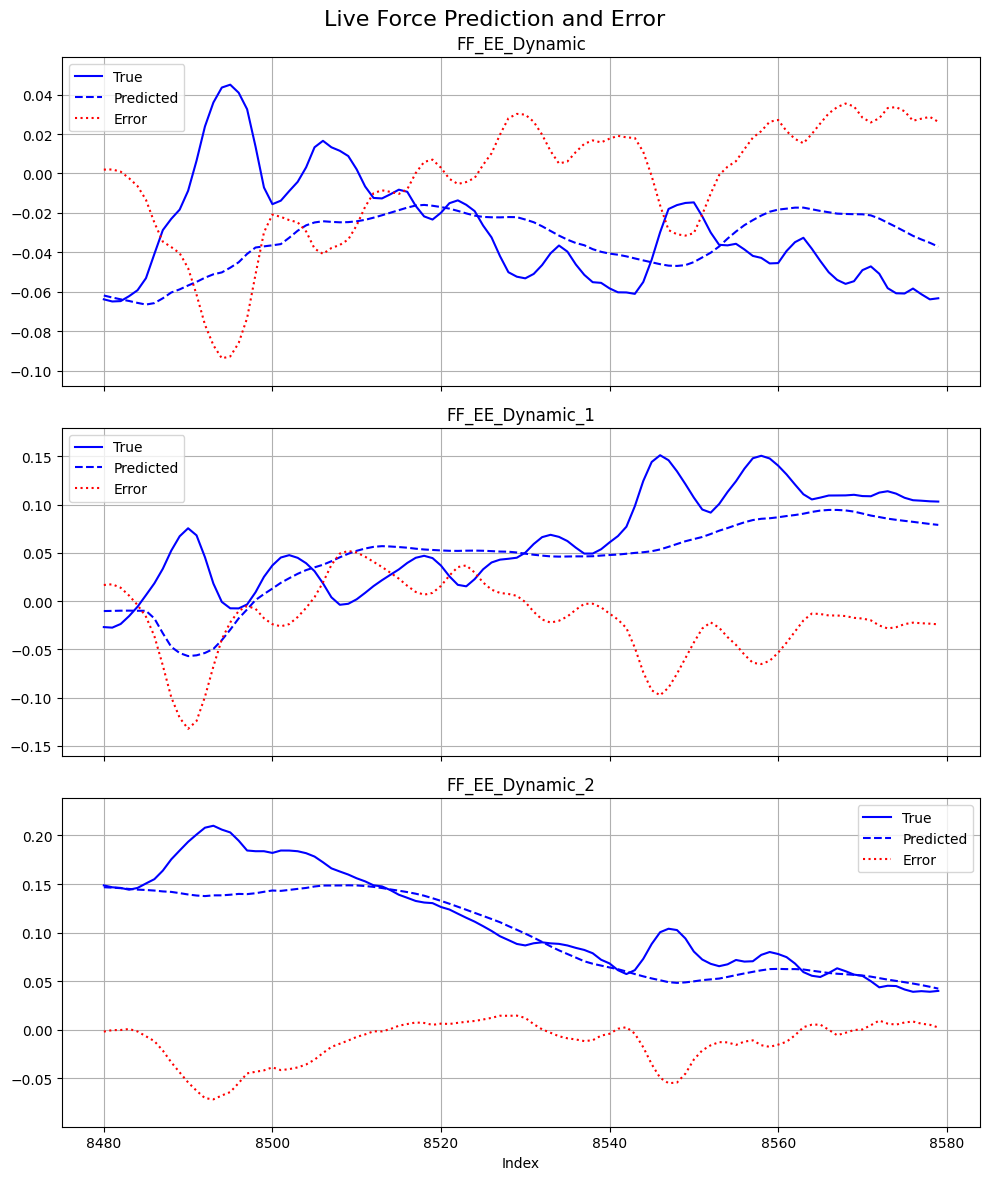

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

# --- 1. Live Plotting Function ---
def plot_live_predictions(model, scaler, df, feature_cols, target_cols, window=100):
    """
    Live plots the predictions of a model on a DataFrame using a for loop.
    
    Args:
        model: The trained MLPRegressor model.
        scaler: The fitted StandardScaler for features.
        df: The DataFrame containing the test data.
        feature_cols: List of column names for model features.
        target_cols: List of column names for the target variable.
        window: The size of the sliding window for the plot.
    """
    # Create the figure and subplots once
    fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
    fig.suptitle('Live Force Prediction and Error', fontsize=16)

    # Set titles and labels for each subplot
    axes[0].set_title('X-Force')
    axes[1].set_title('Y-Force')
    axes[2].set_title('Z-Force')
    axes[2].set_xlabel('Index')
    for ax in axes:
        ax.set_ylabel('Force (N)')
        ax.grid(True)
    
    # Pre-calculate predictions for efficiency
    X_data = df[feature_cols]
    y_data = df[target_cols]
    X_data_scaled = scaler.transform(X_data)
    y_pred_all = model.predict(X_data_scaled)

    # Loop through the data in chunks and update the plot
    for i in range(window, len(df), 20):
        clear_output(wait=True) # Clear previous plot
        
        start = max(0, i - window)
        end = i
        
        # Get the current window of data
        current_y_true = y_data.iloc[start:end].values
        current_y_pred = y_pred_all[start:end]
        errors = current_y_pred - current_y_true
        
        x_indices = np.arange(start, end)
        
        # Clear previous plot lines and draw new ones
        for ax in axes:
            ax.cla()
        
        # Update each plot with new data
        for j in range(3):
            axes[j].plot(x_indices, current_y_true[:, j], label='True', color='blue')
            axes[j].plot(x_indices, current_y_pred[:, j], label='Predicted', linestyle='--', color='blue')
            axes[j].plot(x_indices, errors[:, j], label='Error', linestyle=':', color='red')
            
            # Recalculate y-axis limits dynamically
            all_y_values = np.concatenate([current_y_true[:, j], current_y_pred[:, j], errors[:, j]])
            if all_y_values.size > 0:
                y_min, y_max = np.min(all_y_values), np.max(all_y_values)
                y_range = y_max - y_min if y_max - y_min > 0 else 1.0
                axes[j].set_ylim(y_min - 0.1 * y_range, y_max + 0.1 * y_range)
            axes[j].legend()
            axes[j].grid(True)
            axes[j].set_title(f'{target_cols[j].replace("_0", "")}')

        axes[2].set_xlabel('Index')
        fig.tight_layout()
        display(fig)
        time.sleep(0.05)
    
    plt.close(fig) # Close the last plot
    
# --- 2. Run the live plot ---
plot_live_predictions(mlp, scaler, flattened_test_df, feature_cols, target_cols)

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import time
from tqdm import tqdm

def plot_and_save_frames(model, scaler, df, feature_cols, target_cols, window=100, save_folder='animation_frames'):
    """
    Plots predictions and saves each frame as an image file.
    """
    # Create a directory to save the frames
    if not os.path.exists(save_folder):
        os.makedirs(save_folder)
    
    # Create the figure and subplots once
    fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
    fig.suptitle('Force Prediction and Error', fontsize=16)

    # Set titles and labels for each subplot
    axes[0].set_title('X-Force')
    axes[1].set_title('Y-Force')
    axes[2].set_title('Z-Force')
    axes[2].set_xlabel('Index')
    for ax in axes:
        ax.set_ylabel('Force (N)')
        ax.grid(True)
    
    # Pre-calculate predictions for efficiency
    X_data = df[feature_cols]
    y_data = df[target_cols]
    X_data_scaled = scaler.transform(X_data)
    y_pred_all = model.predict(X_data_scaled)

    # Loop through the data and save each plot as a frame
    frame_count = 0
    for i in tqdm(range(window, len(df), 10), desc="Saving frames"):
        start = max(0, i - window)
        end = i
        
        # Get the current window of data
        current_y_true = y_data.iloc[start:end].values
        current_y_pred = y_pred_all[start:end]
        errors = current_y_pred - current_y_true
        x_indices = np.arange(start, end)
        
        # Clear previous plot lines and draw new ones
        for ax in axes:
            ax.cla()
        
        # Update each plot with new data
        for j in range(3):
            axes[j].plot(x_indices, current_y_true[:, j], label='True', color='blue')
            axes[j].plot(x_indices, current_y_pred[:, j], label='Predicted', linestyle='--', color='blue')
            axes[j].plot(x_indices, errors[:, j], label='Error', linestyle=':', color='red')
            
            # Recalculate y-axis limits dynamically
            all_y_values = np.concatenate([current_y_true[:, j], current_y_pred[:, j], errors[:, j]])
            if all_y_values.size > 0:
                y_min, y_max = np.min(all_y_values), np.max(all_y_values)
                y_range = y_max - y_min if y_max - y_min > 0 else 1.0
                axes[j].set_ylim(y_min - 0.1 * y_range, y_max + 0.1 * y_range)
            axes[j].legend()
            axes[j].grid(True)
            axes[j].set_title(f'{target_cols[j].replace("_0", "")}')

        axes[2].set_xlabel('Index')
        fig.tight_layout()
        
        # Save the frame
        frame_filename = os.path.join(save_folder, f'frame_{frame_count:04d}.png')
        plt.savefig(frame_filename)
        frame_count += 1
    
    plt.close(fig) # Close the last plot
    print(f"\nAll {frame_count} frames saved to '{save_folder}'")

# --- Run the function to save frames ---
plot_and_save_frames(mlp, scaler, flattened_test_df, feature_cols, target_cols)

Saving frames: 100%|██████████| 4971/4971 [29:29<00:00,  2.81it/s]  


All 4971 frames saved to 'animation_frames'


In [ ]:
# --- 6. Calculate Maximum Errors for Each Force Component ---
print("\n" + "="*50)
print("MAXIMUM ERRORS BY FORCE COMPONENT")
print("="*50)

# Calculate errors for each component
errors = y_pred - y_test.values

# Get max errors for each force component
max_errors = np.max(np.abs(errors), axis=0)
component_names = ['Fx', 'Fy', 'Fz']

print(f"{'Component':<10} {'Max Error (N)':<15} {'Max Error (%)':<15}")
print("-" * 45)

for i, (name, max_err) in enumerate(zip(component_names, max_errors)):
    # Calculate percentage error relative to the range of true values
    true_range = np.max(y_test.iloc[:, i]) - np.min(y_test.iloc[:, i])
    max_percentage = (max_err / true_range) * 100 if true_range > 0 else 0
    
    print(f"{name:<10} {max_err:<15.6f} {max_percentage:<15.2f}%")

print("-" * 45)
print(f"{'Overall':<10} {np.max(max_errors):<15.6f} {(np.max(max_errors) / (np.max(y_test.values) - np.min(y_test.values))) * 100:<15.2f}%")

# Additional statistics
print(f"\nDetailed Statistics:")
print(f"Mean Absolute Error (MAE): {np.mean(np.abs(errors), axis=0)}")
print(f"Standard Deviation of Errors: {np.std(errors, axis=0)}")




MAXIMUM ERRORS BY FORCE COMPONENT
Component  Max Error (N)   Max Error (%)  
---------------------------------------------
Fx         0.161973        21.68          %
Fy         0.347796        35.08          %
Fz         0.236585        41.69          %
---------------------------------------------
Overall    0.347796        35.08          %

Detailed Statistics:
Mean Absolute Error (MAE): [0.01851244 0.01660824 0.01558776 0.00220751 0.00204391 0.00137974]
Standard Deviation of Errors: [0.02214888 0.02472304 0.02044558 0.00273986 0.00263964 0.00222394]

MINIMUM ERRORS BY FORCE COMPONENT
Component  Min Error (N)   Min Error (%)  
---------------------------------------------
Fx         -0.161973       -21.68         %
Fy         -0.232493       -23.45         %
Fz         -0.236585       -41.69         %
---------------------------------------------
Overall    -0.236585       -23.87         %

Detailed Statistics:
Min Absolute Error (Min AE): [4.48518803e-08 7.78519378e-07 3.41936290e

In [9]:
# --- 7. Maximum Forces and Predictions Analysis ---
print("\n" + "="*60)
print("MAXIMUM FORCES AND MODEL PREDICTIONS")
print("="*60)

# Find indices of maximum forces for each component
max_force_indices = []
max_force_values = []
max_force_predictions = []

for i, component in enumerate(['Fx', 'Fy', 'Fz']):
    # Find the index of maximum force for this component
    max_idx = y_test.iloc[:, i].idxmax()
    max_force = y_test.iloc[max_idx, i]
    max_prediction = y_pred[max_idx, i]
    
    max_force_indices.append(max_idx)
    max_force_values.append(max_force)
    max_force_predictions.append(max_prediction)
    
    print(f"\n{component} - Maximum Force:")
    print(f"  Index: {max_idx}")
    print(f"  True Value: {max_force:.6f} N")
    print(f"  Predicted: {max_prediction:.6f} N")
    print(f"  Error: {max_prediction - max_force:.6f} N")
    print(f"  Error %: {abs(max_prediction - max_force) / max_force * 100:.2f}%")

# Also show the minimum forces
print("\n" + "-"*60)
print("MINIMUM FORCES AND MODEL PREDICTIONS")
print("-"*60)

min_force_indices = []
min_force_values = []
min_force_predictions = []

for i, component in enumerate(['Fx', 'Fy', 'Fz']):
    # Find the index of minimum force for this component
    min_idx = y_test.iloc[:, i].idxmin()
    min_force = y_test.iloc[min_idx, i]
    min_prediction = y_pred[min_idx, i]
    
    min_force_indices.append(min_idx)
    min_force_values.append(min_force)
    min_force_predictions.append(min_prediction)
    
    print(f"\n{component} - Minimum Force:")
    print(f"  Index: {min_idx}")
    print(f"  True Value: {min_force:.6f} N")
    print(f"  Predicted: {min_prediction:.6f} N")
    print(f"  Error: {min_prediction - min_force:.6f} N")
    print(f"  Error %: {abs(min_prediction - min_force) / abs(min_force) * 100:.2f}%")

# Summary table
print("\n" + "="*60)
print("SUMMARY TABLE")
print("="*60)
print(f"{'Component':<8} {'Max Force':<12} {'Max Pred':<12} {'Max Error':<12} {'Min Force':<12} {'Min Pred':<12} {'Min Error':<12}")
print("-" * 84)

for i, component in enumerate(['Fx', 'Fy', 'Fz']):
    max_err = max_force_predictions[i] - max_force_values[i]
    min_err = min_force_predictions[i] - min_force_values[i]
    
    print(f"{component:<8} {max_force_values[i]:<12.6f} {max_force_predictions[i]:<12.6f} {max_err:<12.6f} {min_force_values[i]:<12.6f} {min_force_predictions[i]:<12.6f} {min_err:<12.6f}")


MAXIMUM FORCES AND MODEL PREDICTIONS

Fx - Maximum Force:
  Index: 49018
  True Value: 0.291777 N
  Predicted: 0.147582 N
  Error: -0.144196 N
  Error %: 49.42%

Fy - Maximum Force:
  Index: 48902
  True Value: 0.429614 N
  Predicted: 0.209798 N
  Error: -0.219816 N
  Error %: 51.17%

Fz - Maximum Force:
  Index: 7020
  True Value: 0.330852 N
  Predicted: 0.195091 N
  Error: -0.135762 N
  Error %: 41.03%

------------------------------------------------------------
MINIMUM FORCES AND MODEL PREDICTIONS
------------------------------------------------------------

Fx - Minimum Force:
  Index: 48931
  True Value: -0.455449 N
  Predicted: -0.412253 N
  Error: 0.043195 N
  Error %: 9.48%

Fy - Minimum Force:
  Index: 48963
  True Value: -0.561727 N
  Predicted: -0.217532 N
  Error: 0.344195 N
  Error %: 61.27%

Fz - Minimum Force:
  Index: 48978
  True Value: -0.236647 N
  Predicted: -0.245972 N
  Error: -0.009325 N
  Error %: 3.94%

SUMMARY TABLE
Component Max Force    Max Pred     Max Er